# 02 - Exploratory Data Analysis

In [10]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

stats_df = pd.read_csv("../data/raw/premier_league_stats_2025_26.csv")
midfielders_df = pd.read_csv("../data/raw/premier_league_midfielders.csv")


display(stats_df.head())
display(midfielders_df.head())    


,player_id,season_id,competition_id,competition_name,team_id,position,rating,appearances,starts,minutes_played,...,duels.aerial_duels_won_percentage,duels.total_duels_won,duels.total_duels_won_percentage,duels.successful_dribbles,duels.successful_dribbles_percentage,discipline.yellow_cards,discipline.red_cards,discipline.direct_red_cards,discipline.penalty_won,discipline.penalty_conceded
0,pl_72501523,sn_6125938,comp_3039,Premier League,tm_7938,M,7.80,29,21,2455,...,NaN,181,NaN,18,NaN,6,0,0,0,0
1,pl_08343894,sn_6125938,comp_3039,Premier League,tm_9145,M,7.70,36,30,3099,...,NaN,195,NaN,14,NaN,3,0,0,0,0
2,pl_29771630,sn_6125938,comp_3039,Premier League,tm_9145,M,6.57,33,16,1900,...,NaN,108,NaN,29,NaN,1,0,0,0,0
3,pl_13495135,sn_6125938,comp_3039,Premier League,tm_9145,M,7.25,24,15,1370,...,NaN,43,NaN,9,NaN,0,0,0,0,0
4,pl_30477667,sn_6125938,comp_3039,Premier League,tm_9145,M,7.13,38,25,3001,...,NaN,218,NaN,7,NaN,4,0,0,0,0


,id,name,first_name,last_name,position,date_of_birth,age,nationality,height_cm,current_team.id,current_team.name,current_team.jersey_number
0,pl_72501523,Bruno Guimarães,Bruno,Guimarães,M,1997-11-16,28.0,Brazil,182.0,tm_9145,Arsenal,39.0
1,pl_72792553,Christos Tzolis,Christos,Tzolis,M,2002-01-30,24.0,Greece,180.0,tm_9145,Arsenal,17.0
2,pl_08343894,Declan Rice,Declan,Rice,M,1999-01-14,27.0,England,188.0,tm_9145,Arsenal,41.0
3,pl_29771630,Eberechi Eze,Eberechi,Eze,M,1998-06-29,28.0,England,178.0,tm_9145,Arsenal,10.0
4,pl_15664649,Maalik Hashi,Maalik,Hashi,M,2008-09-08,18.0,England,178.0,tm_9145,Arsenal,74.0


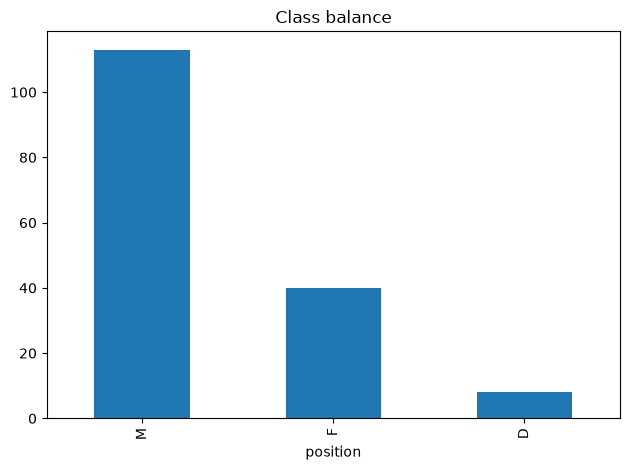

In [ ]:
stats_df["position"].value_counts().plot(kind="bar", title="Class balance")
plt.tight_layout()
plt.show()

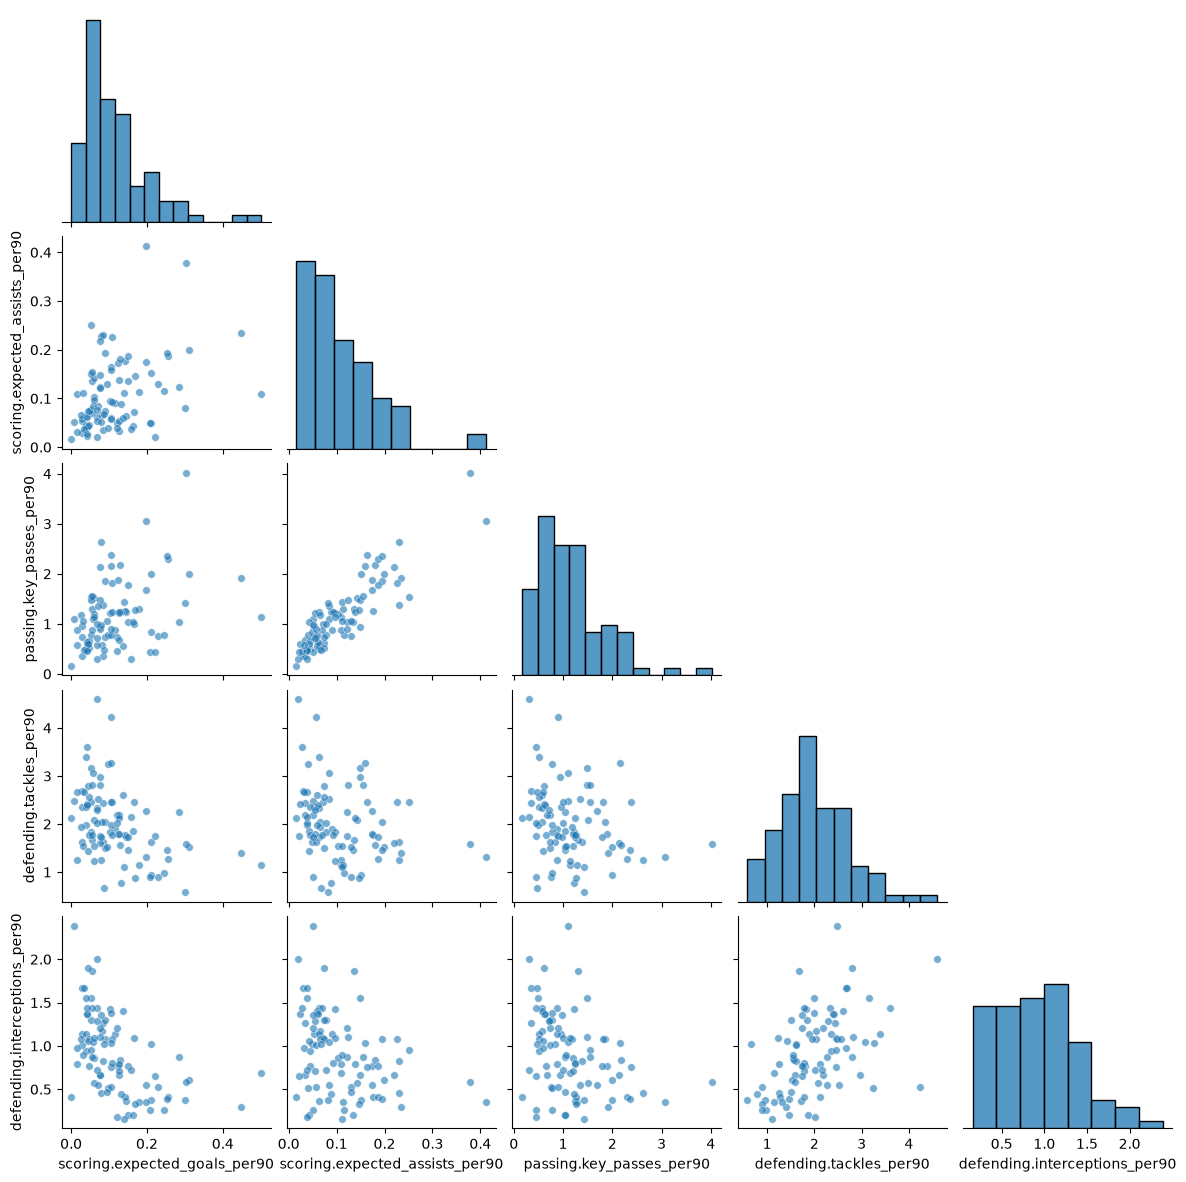

In [16]:
features = [
    "scoring.expected_goals",
    "scoring.expected_assists",
    "passing.key_passes",
    "defending.tackles",
    "defending.interceptions"
]

eda_df = stats_df[
    (stats_df["minutes_played"] >= 450) &
    (stats_df["position"] == "M")
].copy()

for feature in features:
    eda_df[feature + "_per90"] = (
        eda_df[feature] / eda_df["minutes_played"] * 90
    )

per90_features = [feature + "_per90" for feature in features]

sns.pairplot(
    eda_df,
    vars=per90_features,
    corner=True,
    diag_kind="hist",
    plot_kws={"alpha": 0.6, "s": 30},
    height=2.4
)
plt.show()

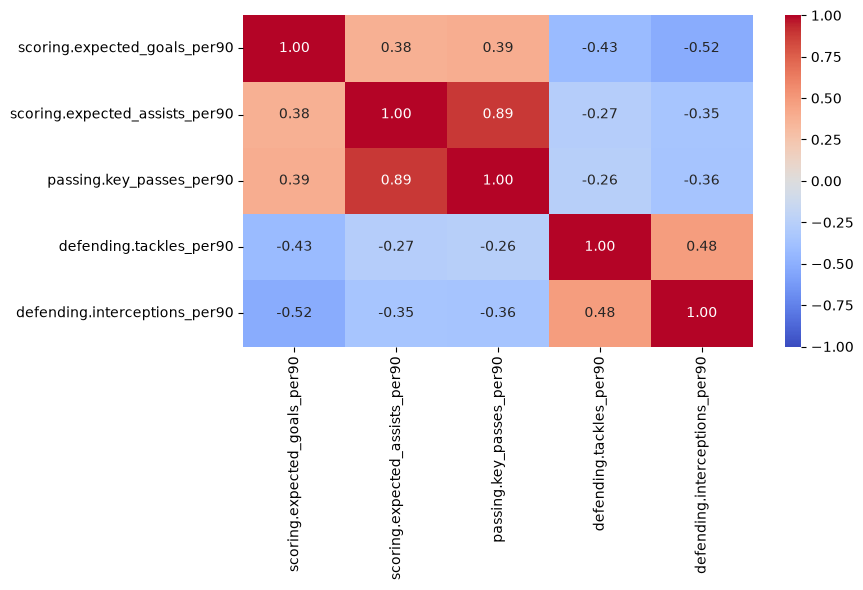

In [18]:
corr = eda_df[per90_features].corr()

plt.figure(figsize=(9, 6))

sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)

plt.tight_layout()
plt.show()